In [1]:
#subject_folder = r"C:/dummy/path/sub-XX"
#subject_folder = "C:/Yoyi/BIDS Dataset/sourcedata/sub-02"
subject_folder = r"C:\Yoyi\Raw Data\1"

# Import Libraries

In [2]:
from BCI2kReader import BCI2kReader as b2k  # Library for reading BCI2000 files
import os                                   # Library to read file directories
import numpy as np                          # Library for array management
import pandas as pd                         # Library for managing data in tables
import matplotlib.pyplot as plt             # Library for plotting data
import math                                 # Library for mathematical operations and constants
import mne                                  # EEG/EMG processing library

# Defines

In [3]:
fs = 512
trialSamples = fs*10
normal_file_size = 14000000
trials_per_run = 32

# Obtain subject id to include in generated figures names
# subject_id = subject_folder.split("sub-")[1].split("/")[0]
subject_id = os.path.split(subject_folder)[1]

output_dir = os.path.join(os.getcwd(), "output")

# Own funtions

In [ ]:
# -------------------------------
# LoadingBCI2000Data
def LoadingBCI2000Data(filename):

    # -------------------------------
    # Load BCI2000 Data
    with b2k.BCI2kReader(filename) as test: # Reading the .dat information
        my_signals, my_states=test.readall() 
    
    # -------------------------------
    # Creating DataFrame
    cols = test.parameters['ChannelNames'] # Headings of the DataFrame and name of the registered channels
    data = pd.DataFrame(my_signals.T, columns=cols) # Adding EEG/EMG data to DataFrame
    data['FE_Motor'] = my_states['XCoordinates'][0] # Adding FE Motor data
    data['RUD_Motor'] = my_states['YCoordinates'][0] # Adding RUD Motor data
    data['TrialInit'] = my_states['TrialInitStamp'][0] # Adding Trial Init event
    data['AllTargetShow'] = my_states['AllTargetShowStamp'][0] # Adding All Target Show event
    data['InitMov'] = my_states['TrialInitMovStamp'][0] # Adding Init Movement event
    data['InitReturnMov'] = my_states['TrialEndMovStamp'][0] # Adding Init Return Movement event
    data['CurrentTarget'] = my_states['CurrentTarget'][0] * 0 # Adding Current Target event (initialized to zero)

    init = data.loc[my_states['TrialInitStamp'][0] == 1].index[0] # Finding the first Trial Init event

    if init > trialSamples:
        init = init - trialSamples
    
    # # Cutting the data to start from the first Trial Init event
    data = data.iloc[init:]

    # # Resetting the index
    data.reset_index(drop=True, inplace=True)

    targets = np.zeros(shape = (trials_per_run), dtype=int)

    # filling the targets array
    for x in range(trials_per_run):
        targets [x] = my_states['CurrentTarget'][0][x*trialSamples + int(trialSamples/2) + 500] # middle of the trial + 0.5 sec (to make sure the target is already shown), during register the event was set at the middle of the trial.
        data.loc[x*trialSamples,'CurrentTarget'] = targets [x]    

    # data2D matrix holds all data from the 40 trials in 2D format (channels x samples), 23 channels: 8 EEG + 8 EMG + FE_Motor + RUD_Motor + 5 events
    data2D = np.zeros(shape=(23,trialSamples*trials_per_run), dtype=np.float32)
    data2D[:,:] = data.iloc[0:trialSamples*trials_per_run].transpose()

    data2D[16,:] = ConvertMotorEncoderToUIDisplacement(motor= "FE", RawData= data2D[16,:])
    data2D[17,:] = ConvertMotorEncoderToUIDisplacement(motor= "RUD", RawData= data2D[17,:])

    for i in range(0,11):
        data2D[16,i] = data2D[16,10];
        data2D[17,i] = data2D[17,10];

    return data2D, cols, targets

# -------------------------------
# ConvertMotorEncoderToUIDisplacement
def ConvertMotorEncoderToUIDisplacement(motor, RawData):
    #Convert data to Rads 
    output = ((RawData * 25) /65535) - 12.5

    if motor == "FE":
        #Convert Rads to Degrees
        output = output*180/math.pi
        #UI Scaling convertion
        for i in range(len(output)):
            if output[i] >= 0:
                output[i] = output[i] * 1.543
            else:
                output[i] = output[i] * 1.559

    elif motor == "RUD":
        #Convert Rads to Degrees
        output = output*-180/math.pi
        #UI Scaling convertion
        for i in range(len(output)):
            if output[i] <= 0:
                output[i] = output[i] * 2.3913
            else:
                output[i] = output[i] * 4.866
    else:
        return 0
    
    return output

#Target Flexion Coordinates (-80,0)
#Target Extension Coordinates (80,0)
#Target RD Coordinates (0,70)
#Target UD Coordinates (0,-70)
#Target D1 Coordinates (-57,50)
#Target D2 Coordinates (57,50)
#Target D3 Coordinates (57,-50)
#Target D4 Coordinates (-57,-50)
EndPoints = {("Flexion", "GO"): (-80, 0),
             ("Flexion", "GO BACK"): (0, 0),
             ("Extension", "GO"): (80, 0),
             ("Extension", "GO BACK"): (0, 0),
             ("Radial D.", "GO"): (0, 70),
             ("Radial D.", "GO BACK"): (0, 0),
             ("Ulnar D.", "GO"): (0, -70),
             ("Ulnar D.", "GO BACK"): (0, 0),
             ("D1", "GO"): (-57, 50),
             ("D1", "GO BACK"): (0, 0),
             ("D2", "GO"): (57, 50),
             ("D2", "GO BACK"): (0, 0),
             ("D3", "GO"): (57, -50),
             ("D3", "GO BACK"): (0, 0),
             ("D4", "GO"): (-57, -50),
             ("D4", "GO BACK"): (0, 0),}

# -------------------------------
# Compute Accuracy
def ComputeAccuracy(movement, RawData, movementDirection):

    Xf, Yf = EndPoints[(movement, movementDirection)]

    if (movementDirection == "GO"):
        Xi, Yi = RawData[0,int(3/4*np.shape(RawData)[1])-1], RawData[1,int(3/4*np.shape(RawData)[1])-1]
    elif (movementDirection == "GO BACK"):
        Xi, Yi = RawData[0,np.shape(RawData)[1]-1], RawData[1,np.shape(RawData)[1]-1]
        
    accuracy = math.sqrt((Xi - Xf)**2 + (Yi - Yf)**2)

    return accuracy

# -------------------------------
# Compute Excecution Time
def ComputeExcecutionTime(movement, RawData, movementDirection):

    Xf, Yf = EndPoints[(movement, movementDirection)]

    if (movementDirection == "GO"):
        indexI = int(1/2*np.shape(RawData)[1])-1
        indexF = int(3/4*np.shape(RawData)[1])-1
        timeOffset = 5
    elif (movementDirection == "GO BACK"):
        indexI = int(3/4*np.shape(RawData)[1])-1
        indexF = np.shape(RawData)[1]-1
        timeOffset = 7.5

    targetHit = False

    for i in range(indexI, indexF):
        distance = math.sqrt((RawData[0,i] - Xf)**2 + (RawData[1,i] - Yf)**2)
        if distance <= 8:
            if targetHit == False:
                elapsed_time = i/fs        
                ExcecutionTime = elapsed_time - timeOffset
                targetHit = True
        else:
            targetHit = False 
                    
    if targetHit == False:
        return np.nan
    elif targetHit == True:
        return ExcecutionTime

# -------------------------------
# Ideal trayectories defined to compute the Mean Square Error
#Target Flexion Coordinates (-80,0)
#Target Extension Coordinates (80,0)
#Target RD Coordinates (0,70)
#Target UD Coordinates (0,-70)
Center_to_F_Ideal_Trayectory = np.arange(0,-80,-80/(2.5*fs))
Center_to_E_Ideal_Trayectory = np.arange(0,80,80/(2.5*fs))
Center_to_RD_Ideal_Trayectory = np.arange(0,70,70/(2.5*fs))
Center_to_UD_Ideal_Trayectory = np.arange(0,-70,-70/(2.5*fs))
F_to_Center_Ideal_Trayectory = np.arange(-80,0,80/(2.5*fs))
E_to_Center_Ideal_Trayectory = np.arange(80,0,-80/(2.5*fs))
RD_to_Center_Ideal_Trayectory = np.arange(70,0,-70/(2.5*fs)) 
UD_to_Center_Ideal_Trayectory = np.arange(-70,0,70/(2.5*fs))
Traverse_Ideal_Trayectory = np.zeros(shape=int(2.5*fs), dtype=np.float32)

# -------------------------------
# Compute Trayectory Efficiency(Trayectory Real distance/ Ideal Trayectory distance)

def ComputeTrayectoryEfficiency(movement, RawData, movementDirection):
    
    if (movementDirection == "GO"):
        Current_Trayectory = RawData[:,int(1/2*np.shape(RawData)[1]):int(3/4*np.shape(RawData)[1])]
    elif (movementDirection == "GO BACK"):
        Current_Trayectory = RawData[:,int(3/4*np.shape(RawData)[1]):np.shape(RawData)[1]]

    IdealTrayectoryDistance = math.sqrt((Current_Trayectory[0,np.shape(Current_Trayectory)[1]-1] - Current_Trayectory[0,0])**2 + (Current_Trayectory[1,np.shape(Current_Trayectory)[1]-1] - Current_Trayectory[1,0])**2)

    PartialDistanceTraveled = 0

    for i in range(np.shape(Current_Trayectory)[1]-1):
        #The total distance traveled between each pair of points on the path is calculated.
        PartialDistanceTraveled = PartialDistanceTraveled + math.sqrt((Current_Trayectory[0,i+1] - Current_Trayectory[0,i])**2 + (Current_Trayectory[1,i+1] - Current_Trayectory[1,i])**2)
    
    if IdealTrayectoryDistance == 0:
        return 0

    TrayectoryEfficiency = PartialDistanceTraveled / IdealTrayectoryDistance
    return TrayectoryEfficiency

import re

# -------------------------------
# _parse_subject_id
def _parse_subject_id(subject_id) -> int:
    """
    Extract the numeric part from subject_id.
    Accepts formats like: 5, "5", "sub-05", "sub-5", "sub-24".
    Returns the integer subject number (e.g., 5, 24).
    """
    s = str(subject_id)
    m = re.search(r"(\d+)", s)
    if not m:
        raise ValueError(f"subject_id '{subject_id}' does not contain a number.")
    return int(m.group(1))

# -------------------------------
# update_subject_trials
def update_subject_trials(subject_id,
                          eeg_trials: int | None = None,
                          emg_trials: int | None = None,
                          outfile: str = "trials_per_subject.tsv") -> None:
    """
    Maintain a TSV file where:
      - each row corresponds to a subject (numeric ID: 1, 2, 3, ...)
      - there are exactly two metric columns:
          * RemainingTrialsEEG
          * RemainingTrialsEMG

    This function can be called from:
      - the EEG analysis script (only eeg_trials is provided), or
      - the EMG analysis script (only emg_trials is provided).

    The function:
      - creates the file if it does not exist,
      - adds the subject row if it does not exist,
      - updates only the metrics that are provided (EEG and/or EMG),
      - always sorts rows by subject ID in ascending order.
    """

    # Normalize subject_id -> numeric (e.g. 'sub-05' -> 5)
    sid = _parse_subject_id(subject_id)

    # 1) Load existing file if present and non-empty
    if os.path.exists(outfile) and os.path.getsize(outfile) > 0:
        df = pd.read_csv(outfile, sep="\t")
        # Ensure required columns exist
        for col in ["subject", "RemainingTrialsEEG", "RemainingTrialsEMG"]:
            if col not in df.columns:
                raise ValueError(
                    f"File '{outfile}' does not have the expected column '{col}'. "
                    "Delete it or fix it before using this function."
                )
    else:
        # Start from an empty DataFrame with the expected columns
        df = pd.DataFrame(columns=["subject", "RemainingTrialsEEG", "RemainingTrialsEMG"])

    # 2) Ensure 'subject' is integer
    if len(df) > 0:
        df["subject"] = df["subject"].astype(int)

    # 3) Check if subject already exists
    mask = df["subject"] == sid
    if not mask.any():
        # Create new row with NaN in both metrics
        new_row = {
            "subject": sid,
            "RemainingTrialsEEG": np.nan,
            "RemainingTrialsEMG": np.nan,
        }
        df = pd.concat([df, pd.DataFrame([new_row])], ignore_index=True)

        # Rebuild mask for the new subject
        mask = df["subject"] == sid

    # 4) Update only provided metrics
    if eeg_trials is not None:
        df.loc[mask, "RemainingTrialsEEG"] = int(eeg_trials)
    if emg_trials is not None:
        df.loc[mask, "RemainingTrialsEMG"] = int(emg_trials)

    # 5) Sort rows by subject numeric ID
    df = df.sort_values("subject").reset_index(drop=True)

    # 6) Save to TSV
    df.to_csv(outfile, sep="\t", index=False)

# Load BCI2000 Data

In [5]:
#subject_folder = subject_folder + "/ses-01/eeg/"
subject_folder = subject_folder + r"\001"
files = os.listdir(subject_folder) # List of files in the folder
goodFiles = []

for i in range(len(files)):
    if (files[i].endswith(".dat") and (os.path.getsize(subject_folder + r'\\' + files[i]) > normal_file_size)): # Selecting only .dat files larger than 9MB, the  training file, or any incomplete file is excluded from the analysis
        goodFiles.append(files[i])

# Excluding the first and last files, this are the pre and post basal register files, excluded from the analysis, as they do not contain the motor task
del goodFiles[0]
del goodFiles[len(goodFiles)- 1]

data3D = np.zeros(shape=(23,trialSamples*trials_per_run,len(goodFiles)), dtype=np.float32)
targets2D = np.zeros(shape=(trials_per_run,len(goodFiles)), dtype=int)

for i in range(len(goodFiles)):
    data2D_temp, cols_temp, targets_temp = LoadingBCI2000Data(subject_folder+"\\"+goodFiles[i])
    data3D[:,:,i] = data2D_temp
    targets2D[:,i] = targets_temp

# Construct MNE object and data preprocessing

(304, 8, 5120)
Global minimum value: -0.0011958911512908274
Global maximum value: 0.0009824241486077856


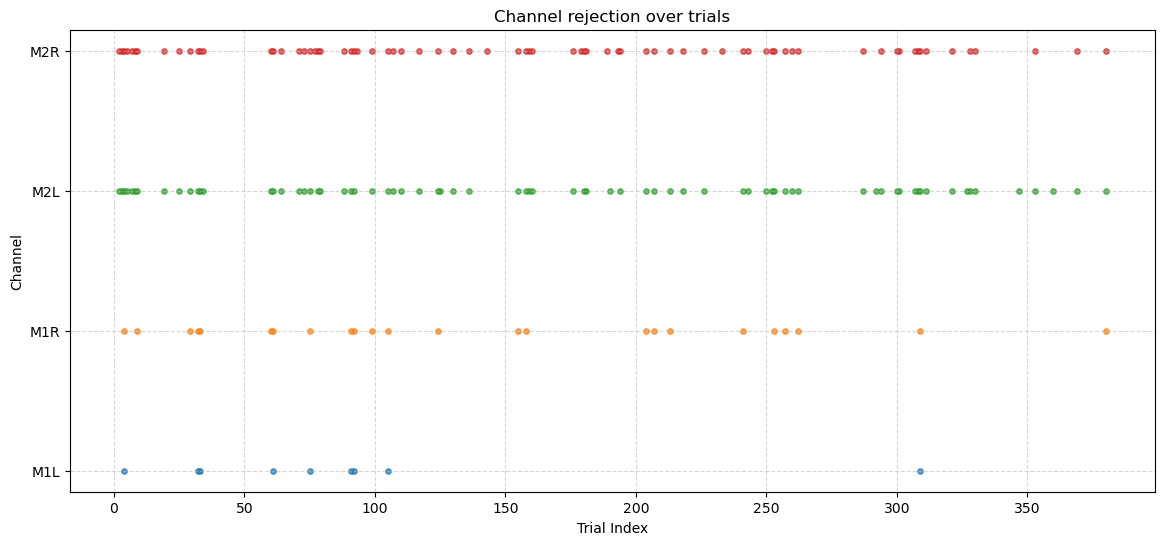

In [6]:

# -------------------------------
# Info
ChannelNames = cols_temp
Nchannels, Nsamples  = (data3D[8:16,:,1]).shape # Considering the 8 EMG channels
EMG_Nchannels = int(Nchannels)
t             = np.linspace(0, 1/fs, Nsamples)
# -------------------------------
# In values and units of V for EEG data
data3D[8:16,:,:] = data3D[8:16,:,:] *1e-6

# -------------------------------
# Construct a MNE data object
info          = mne.create_info(ch_names=ChannelNames[8:16], sfreq=fs, ch_types=['eeg']*EMG_Nchannels, verbose=False) #eeg channels type selected in order to used some of the build-in MNE functions

info["description"] = "EEG-EMG-WristMotion Dataset"

# Construct event_id, a dictionary to map the target event names to IDs
event_id= {"Flexion":1, "Extension":2, "Radial D.":3, "Ulnar D.":4}

#Generate Raw objects for EMG and Kinematic data
RawDataEMG = [None] * (data3D.shape[2])
RawDataKinematic = [None] * (data3D.shape[2])
epochsEMG_array = []
epochsKinematic_array = []

for i in range(0, data3D.shape[2]):
    # Construct events
    events = np.column_stack((
        np.linspace(0, targets2D[:,i].size-1, targets2D[:,i].size, dtype=int)*trialSamples,
        np.zeros(targets2D[:,i].size, dtype=int),
        targets2D[:,i],
    ))

    # Create Raw object from EEG data
    info = mne.create_info(ch_names=ChannelNames[8:16], sfreq=fs, ch_types=['eeg']*EMG_Nchannels, verbose=False) #eeg channels type selected in order to used some of the build-in MNE functions
    info["description"] = "EEG-EMG-WristMotion Dataset"
    RawDataEMG[i] = mne.io.RawArray(data3D[8:16,:,i], info, verbose=False)
    info          = mne.create_info(ch_names=['FES_Motor', 'RUD_Motor'], sfreq=fs, verbose=False)
    RawDataKinematic[i] = mne.io.RawArray(data3D[16:18,:,i], info, verbose=False)

    # Apply bandpass filter for EMG
    RawDataEMG[i].filter(l_freq=20, h_freq=250, picks='all', verbose=False)

    # Apply bandpass filter for Kinemtaics
    RawDataKinematic[i].filter(l_freq=None, h_freq=250, picks='all', method='iir', verbose=False)


    # Construct MNE Epochs object, extracting epochs from 0 to 10 seconds after each TrialInit event, with baseline correction and rejection of epochs with peak-to-peak amplitude higher than 1 mV
    epochsEMG_array.append(mne.Epochs(RawDataEMG[i], tmin=0, tmax=10-1/fs, events=events, baseline=(None,None), verbose=False, preload=True, reject = {"eeg": 2e-3}))
    epochsKinematic_array.append(mne.Epochs(RawDataKinematic[i], tmin=0, tmax=10-1/fs, events=events, baseline=None, verbose=False, preload=True))

epochsEMG = mne.concatenate_epochs(epochsEMG_array[:], verbose=False)
epochsKinematic = mne.concatenate_epochs(epochsKinematic_array[:], verbose=False)

# -------------------------------
# Get a temporal epochs object
epochstmp = epochsEMG.copy()

data_array = epochsEMG.get_data()
print(data_array.shape)

print(f"Global minimum value: {data_array.min()}")
print(f"Global maximum value: {data_array.max()}")

#checking rejections

# Channels of interest
channels = ['M1L', 'M1R', 'M2L', 'M2R', 'M3L', 'M3R', 'M4L', 'M4R']

# Save indexes of the trials where each channel was rejected
rejections_by_channel = {ch: [] for ch in channels}
for i, trial in enumerate(epochsEMG.drop_log):
    for ch in trial:
        if ch in rejections_by_channel:
            rejections_by_channel[ch].append(i)

# Scatter Plot
plt.figure(figsize=(14, 6))
for ch, indices in rejections_by_channel.items():
    plt.scatter(indices, [ch] * len(indices), label=ch, alpha=0.7, s=15)

plt.xlabel("Trial Index")
plt.ylabel("Channel")
plt.title("Channel rejection over trials")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

# Save remaining trials to tsv file
output_path = os.path.join(output_dir, f"trials_per_subject.tsv")
update_subject_trials(
    subject_id=subject_id,
    eeg_trials=None,                # Don´t touch EEG
    emg_trials=int(data_array.shape[0]),              
    outfile=output_path
)

# #end checking

# 1) EMG vs Encoder Data

Dropped 80 epochs: 2, 3, 4, 5, 7, 8, 9, 19, 25, 29, 32, 33, 34, 60, 61, 64, 71, 73, 75, 77, 78, 79, 88, 91, 92, 93, 99, 105, 107, 110, 117, 124, 125, 130, 136, 143, 155, 158, 159, 160, 176, 179, 180, 181, 189, 190, 193, 194, 204, 207, 213, 218, 226, 233, 241, 243, 250, 252, 253, 257, 260, 262, 287, 292, 294, 300, 301, 307, 308, 309, 311, 321, 327, 328, 330, 347, 353, 360, 369, 380
Trial 290 (flexion)
Trial 109 (radial deviation)


C:\Users\jorge\AppData\Local\Temp\ipykernel_19436\2064850050.py:156: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


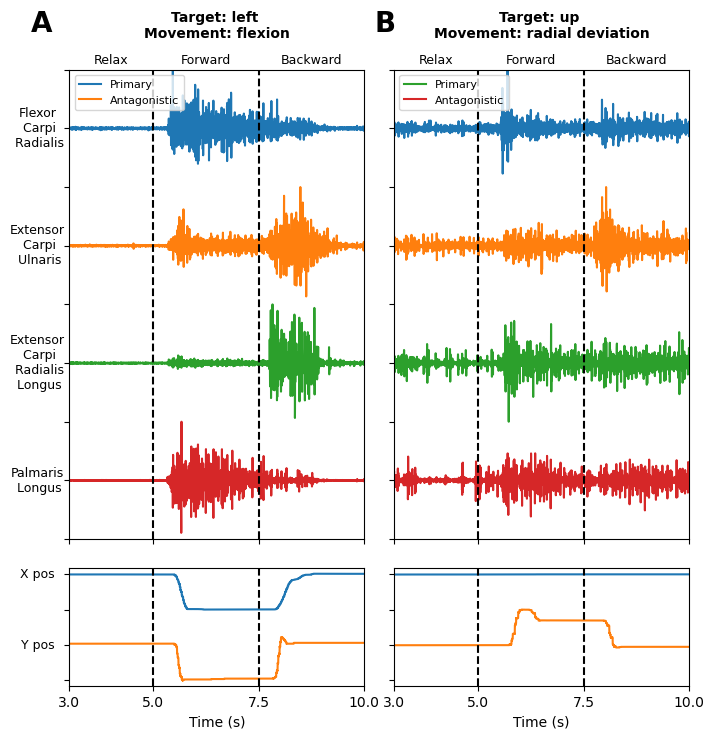

In [7]:
data3D_EMG = epochsEMG.get_data() # Get all epochs data in a 3D matrix (trials x channels x samples
epochsKinematictmp = epochsKinematic.copy()

dropped_indices = [n for n, dl in enumerate(epochsEMG.drop_log) if len(dl)] # Indices of rejected epochs
epochsKinematictmp = epochsKinematictmp.drop(dropped_indices) # Drop corresponding kinematic epochs

data3D_Kinematic = epochsKinematictmp.get_data() #


time = np.zeros(shape=(data3D_EMG.shape[2]), dtype=np.float32)
targets = epochsEMG.events[:,2]
muscle1 = muscle2 = muscle3 = muscle4 = np.zeros(shape=(data3D_EMG.shape[2]), dtype=np.float32)

movement = {1: "flexion", 2: "extension", 3: "radial deviation", 4: "ulnar deviation", 5: "D1", 6: "D2", 7: "D3", 8: "D4"}
target = {1: "left", 2: "right", 3: "up", 4: "down", 5: "D1", 6: "D2", 7: "D3", 8: "D4"}

for x in range(data3D_EMG.shape[2]):
    time[x] = x * 1/fs

#select a random flexion trial
movement_code = 1       # 1=Flexión
indices = np.where(targets == movement_code)[0]

selected_trial = np.random.choice(indices) #Trial to be plotted
#muscle data 
muscle1 = data3D_EMG[selected_trial,0,:] - data3D_EMG[selected_trial,1,:] #Extensor Carpi Radialis Longus, associated with the radial deviation movement
muscle2 = data3D_EMG[selected_trial,2,:] - data3D_EMG[selected_trial,3,:] #Extensor Carpi Ulnaris, associated with the extension movement
muscle3 = data3D_EMG[selected_trial,4,:] - data3D_EMG[selected_trial,5,:] #Flexor Carpi Radialis, associated with the flexion movement
muscle4 = data3D_EMG[selected_trial,6,:] - data3D_EMG[selected_trial,7,:] #Palmaris Longus, associated with the ulnar deviation movement
NormalizedMuscle1 = muscle1/np.max(np.abs(muscle1))
NormalizedMuscle2 = muscle2/np.max(np.abs(muscle2))
NormalizedMuscle3 = muscle3/np.max(np.abs(muscle3))
NormalizedMuscle4 = muscle4/np.max(np.abs(muscle4))
X = data3D_Kinematic[selected_trial,0,:]
Y = data3D_Kinematic[selected_trial,1,:]

#If variance is lower than a threshold, then normalize against the value reported in the literature
if np.var(X) < 1:
    NormalizedX = X / 90
else:
    NormalizedX = X/np.max(np.abs(X))
if np.var(Y) < 1:
    NormalizedY = Y / 45
else:
    NormalizedY = Y/np.max(np.abs(Y))

if 1:#target[targets[selected_trial]] == "up" or target[targets[selected_trial]] == "down":
    print("Trial %d (%s)" %(selected_trial,movement[targets[selected_trial]]))
    from matplotlib import gridspec
    
    fig,axs = plt.subplots(2,2, figsize=(8, 8), sharex='col', sharey='row', gridspec_kw={
                    'height_ratios': [4, 1],
                    'wspace': 0.1,
                    'hspace': 0.1})
    axs[0,0].set_title("Target: {} \nMovement: {}".format(target[targets[selected_trial]], movement[targets[selected_trial]]), fontsize=10, y=1.05, fontweight='bold')
    axs[0,0].plot(time[1536:], NormalizedMuscle3[1536:] + 6, label='Primary')
    axs[0,0].plot(time[1536:], NormalizedMuscle2[1536:] + 4, label='Antagonistic')
    axs[0,0].plot(time[1536:], NormalizedMuscle1[1536:] + 2)
    axs[0,0].plot(time[1536:], NormalizedMuscle4[1536:])
    axs[0,0].axvline(x = 5.0, color= 'black', linestyle = 'dashed')  
    axs[0,0].axvline(x = 7.5, color= 'black', linestyle = 'dashed')
    xticks = [3, 5, 7.5, 10]
    axs[0,0].set_xticks(xticks)
    axs[0,0].set_yticklabels([]) 
    axs[0,0].set_xlim(3,10)
    axs[0,0].set_ylim(-1.,7.)
    axs[0,0].legend(loc='upper left', fontsize=8)



    xmin = axs[0,0].get_xlim()[0] #(previous y location: 0, 2.5, 5, 7.5)
    axs[0,0].text(xmin-0.75, 0, 'Palmaris\n Longus', ha='center', va='center', fontsize=9, rotation=0, color='k', zorder=11)
    axs[0,0].text(xmin-0.75, 2, 'Extensor\n Carpi\n Radialis\n Longus', ha='center', va='center', fontsize=9, rotation=0, color='k', zorder=11)
    axs[0,0].text(xmin-0.75, 4, 'Extensor\n Carpi\n Ulnaris', ha='center', va='center', fontsize=9, rotation=0, color='k', zorder=11)
    axs[0,0].text(xmin-0.75, 6, 'Flexor\n Carpi\n Radialis', ha='center', va='center', fontsize=9, rotation=0, color='k', zorder=11)
    # add text just above the top axis
    ymax = axs[0,0].get_ylim()[1]
    axs[0,0].text(4, ymax+0.05, 'Relax', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11)
    axs[0,0].text(6.25, ymax+0.05, 'Forward', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11)
    axs[0,0].text(8.75, ymax+0.05, 'Backward', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11)
    axs[1,0].set_xlabel('Time (s)')
    axs[1,0].plot(time[1536:], NormalizedX[1536:] + 2)
    axs[1,0].plot(time[1536:], NormalizedY[1536:])
    axs[1,0].axvline(x = 5.0, color= 'black', linestyle = 'dashed')  
    axs[1,0].axvline(x = 7.5, color= 'black', linestyle = 'dashed')
    xticks = [3, 5, 7.5, 10]
    axs[1,0].set_xticks(xticks)
    axs[1,0].set_yticklabels([]) 
    # add text just left the left axis
    xmin = axs[1,0].get_xlim()[0]
    axs[1,0].text(xmin-0.75, 0, 'Y pos', ha='center', va='center', fontsize=9, rotation=0, color='k', zorder=11)
    axs[1,0].text(xmin-0.75, 2, 'X pos', ha='center', va='center', fontsize=9, rotation=0, color='k', zorder=11)

    # the other two grpahs

    #select a random radial deviation trial
    movement_code = 3       # 3=Radial Deviation
    indices = np.where(targets == movement_code)[0]

    selected_trial = np.random.choice(indices) #Trial to be plotted
    print("Trial %d (%s)" %(selected_trial,movement[targets[selected_trial]]))
    #muscle data 
    muscle1 = data3D_EMG[selected_trial,0,:] - data3D_EMG[selected_trial,1,:] #Extensor Carpi Radialis Longus, associated with the radial deviation movement
    muscle2 = data3D_EMG[selected_trial,2,:] - data3D_EMG[selected_trial,3,:] #Extensor Carpi Ulnaris, associated with the extension movement
    muscle3 = data3D_EMG[selected_trial,4,:] - data3D_EMG[selected_trial,5,:] #Flexor Carpi Radialis, associated with the flexion movement
    muscle4 = data3D_EMG[selected_trial,6,:] - data3D_EMG[selected_trial,7,:] #Palmaris Longus, associated with the ulnar deviation movement
    NormalizedMuscle1 = muscle1/np.max(np.abs(muscle1))
    NormalizedMuscle2 = muscle2/np.max(np.abs(muscle2))
    NormalizedMuscle3 = muscle3/np.max(np.abs(muscle3))
    NormalizedMuscle4 = muscle4/np.max(np.abs(muscle4))
    X = data3D_Kinematic[selected_trial,0,:]
    Y = data3D_Kinematic[selected_trial,1,:]
    #If variance is lower than a threshold, then normalize against the value reported in the literature
    if np.var(X) < 1:
        NormalizedX = X / 90
    else:
        NormalizedX = X/np.max(np.abs(X))
    if np.var(Y) < 1:
        NormalizedY = Y / 45
    else:
        NormalizedY = Y/np.max(np.abs(Y))

    axs[0,1].set_title("Target: {} \nMovement: {}".format(target[targets[selected_trial]], movement[targets[selected_trial]]), fontsize=10, y=1.05, fontweight='bold')
    axs[0,1].plot(time[1536:], NormalizedMuscle3[1536:] + 6)
    axs[0,1].plot(time[1536:], NormalizedMuscle2[1536:] + 4)
    axs[0,1].plot(time[1536:], NormalizedMuscle1[1536:] + 2, label='Primary')
    axs[0,1].plot(time[1536:], NormalizedMuscle4[1536:], label='Antagonistic')

    axs[0,1].axvline(x = 5.0, color= 'black', linestyle = 'dashed')  
    axs[0,1].axvline(x = 7.5, color= 'black', linestyle = 'dashed')
    xticks = [3, 5, 7.5, 10]
    axs[0,1].set_xticks(xticks)
    axs[0,1].set_yticklabels([])
    axs[0,1].set_xlim(3,10)
    axs[0,1].set_ylim(-1.,7.) 
    axs[0,1].legend(loc='upper left', fontsize=8)

    # add text just above the top axis
    ymax = axs[0,1].get_ylim()[1]
    axs[0,1].text(4, ymax+0.05, 'Relax', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11)
    axs[0,1].text(6.25, ymax+0.05, 'Forward', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11)
    axs[0,1].text(8.75, ymax+0.05, 'Backward', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11)
    axs[1,1].set_xlabel('Time (s)')
    axs[1,1].plot(time[1536:], NormalizedX[1536:] + 2)
    axs[1,1].plot(time[1536:], NormalizedY[1536:])
    axs[1,1].axvline(x = 5.0, color= 'black', linestyle = 'dashed')  
    axs[1,1].axvline(x = 7.5, color= 'black', linestyle = 'dashed')
    xticks = [3, 5, 7.5, 10]
    axs[1,1].set_xticks(xticks)
    axs[1,1].set_yticklabels([]) 

    fig.text(0.09, 0.92, 'A', ha='center', va='bottom', fontsize=20, rotation=0, color='k', zorder=11, fontweight='bold')
    fig.text(0.52, 0.92, 'B', ha='center', va='bottom', fontsize=20, rotation=0, color='k', zorder=11, fontweight='bold')
    

    fig.tight_layout()
    plt.show()

    output_path = os.path.join(output_dir, f"sub-{subject_id}_EMG.pdf")
    fig.savefig(output_path, dpi=600, bbox_inches='tight') # Save the figure

# 2) Encoder Data

Dropped 4 epochs: 30, 114, 174, 224


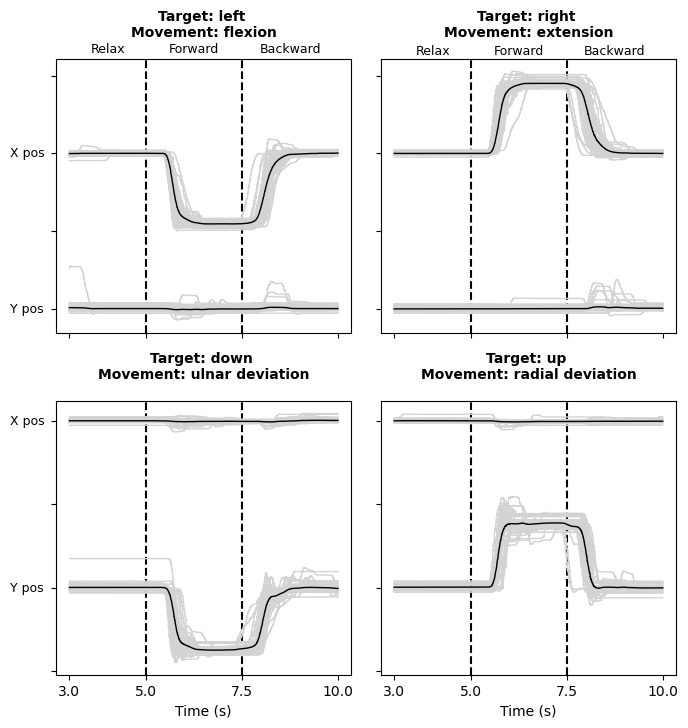

Text(0.5, 0, 'Time (s)')

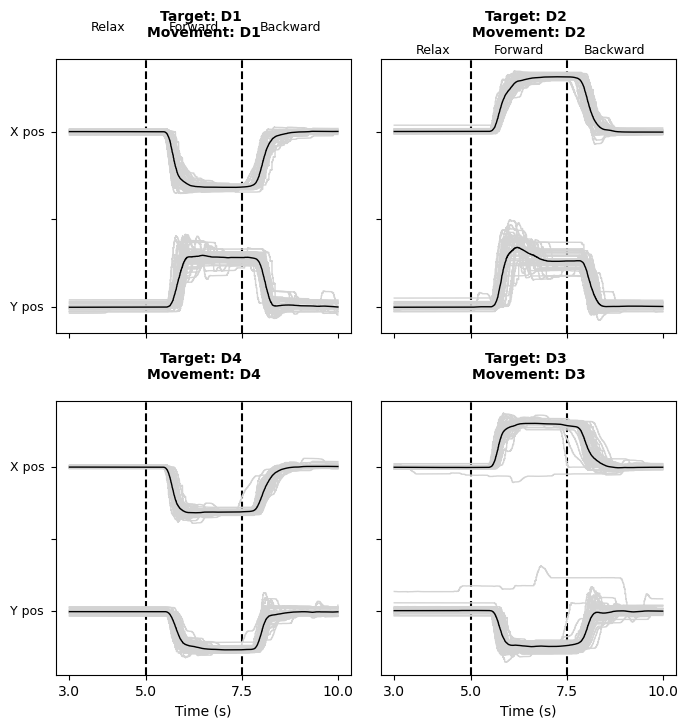

In [14]:
epochsKinematictmp = epochsKinematic.copy()

def custom_rejection_criteria(epoch_data):
    # Define custom rejection criteria
    max_amplitude = 100  # Example threshold in units of the data
    if (np.max(np.abs(epoch_data), axis=1) > max_amplitude).any():
        return True  # Reject epoch
    return False  # Keep epoch  

# Apply the custom function to each epoch to create a boolean mask
# This creates a list of booleans, where True means the epoch is "bad" according to the function
bad_epochs_mask = [custom_rejection_criteria(epoch) for epoch in epochsKinematictmp.get_data()]

# Drop the bad epochs using the mask
# The 'drop' method can take a boolean mask or indices
epochsKinematictmp.drop(bad_epochs_mask, reason='custom_criteria')

data3D_Kinematic = epochsKinematictmp.get_data() #

event_id= {"Flexion":1, "Extension":2, "Radial D.":3, "Ulnar D.":4}
data3D_Kinematic_Flexion = epochsKinematictmp['1'].get_data()
data3D_Kinematic_Extension = epochsKinematictmp['2'].get_data()
data3D_Kinematic_Radial = epochsKinematictmp['3'].get_data()
data3D_Kinematic_Ulnar = epochsKinematictmp['4'].get_data()

data3D_D1 = epochsKinematictmp['5'].get_data()
data3D_D2 = epochsKinematictmp['6'].get_data()
data3D_D3 = epochsKinematictmp['7'].get_data()
data3D_D4 = epochsKinematictmp['8'].get_data()

Normalized_Flexion = np.zeros(shape=(data3D_Kinematic_Flexion.shape[0], data3D_Kinematic_Flexion.shape[1], data3D_Kinematic_Flexion.shape[2]), dtype=np.float32)
Normalized_Extension = np.zeros(shape=(data3D_Kinematic_Extension.shape[0], data3D_Kinematic_Extension.shape[1], data3D_Kinematic_Extension.shape[2]), dtype=np.float32)
Normalized_Radial = np.zeros(shape=(data3D_Kinematic_Radial.shape[0], data3D_Kinematic_Radial.shape[1], data3D_Kinematic_Radial.shape[2]), dtype=np.float32)
Normalized_Ulnar = np.zeros(shape=(data3D_Kinematic_Ulnar.shape[0], data3D_Kinematic_Ulnar.shape[1], data3D_Kinematic_Ulnar.shape[2]), dtype=np.float32)

Normalized_D1 = np.zeros(shape=(data3D_D1.shape[0], data3D_D1.shape[1], data3D_D1.shape[2]), dtype=np.float32)
Normalized_D2 = np.zeros(shape=(data3D_D2.shape[0], data3D_D2.shape[1], data3D_D2.shape[2]), dtype=np.float32)
Normalized_D3 = np.zeros(shape=(data3D_D3.shape[0], data3D_D3.shape[1], data3D_D3.shape[2]), dtype=np.float32)
Normalized_D4 = np.zeros(shape=(data3D_D4.shape[0], data3D_D4.shape[1], data3D_D4.shape[2]), dtype=np.float32)

flex_count = extension_count = radial_count = ulnar_count = D1_count = D2_count = D3_count = D4_count = 0

targets = epochsKinematictmp.events[:,2]

time = np.zeros(shape=(data3D_Kinematic.shape[2]), dtype=np.float32)

for x in range(data3D_Kinematic.shape[2]):
    time[x] = x * 1/fs



for selected_trial in range(0,epochsKinematictmp.get_data().shape[0]):
    #encoders data
    X = data3D_Kinematic[selected_trial,0,:]
    Y = data3D_Kinematic[selected_trial,1,:]
    NormalizedY = Y / 90
    NormalizedX = X / 90
    
    if targets[selected_trial] == 1:        
        Normalized_Flexion[flex_count,0,:] = NormalizedX
        Normalized_Flexion[flex_count,1,:] = NormalizedY
        flex_count += 1
    elif targets[selected_trial] == 2:
        Normalized_Extension[extension_count,0,:] = NormalizedX
        Normalized_Extension[extension_count,1,:] = NormalizedY
        extension_count += 1
    elif targets[selected_trial] == 3:
        Normalized_Radial[radial_count,0,:] = NormalizedX
        Normalized_Radial[radial_count,1,:] = NormalizedY
        radial_count += 1
    elif targets[selected_trial] == 4:
        Normalized_Ulnar[ulnar_count,0,:] = NormalizedX
        Normalized_Ulnar[ulnar_count,1,:] = NormalizedY
        ulnar_count += 1
    elif targets[selected_trial] == 5:
        Normalized_D1[D1_count,0,:] = NormalizedX
        Normalized_D1[D1_count,1,:] = NormalizedY
        D1_count += 1
    elif targets[selected_trial] == 6:
        Normalized_D2[D2_count,0,:] = NormalizedX
        Normalized_D2[D2_count,1,:] = NormalizedY
        D2_count += 1
    elif targets[selected_trial] == 7:
        Normalized_D3[D3_count,0,:] = NormalizedX
        Normalized_D3[D3_count,1,:] = NormalizedY
        D3_count += 1
    elif targets[selected_trial] == 8:
        Normalized_D4[D4_count,0,:] = NormalizedX
        Normalized_D4[D4_count,1,:] = NormalizedY
        D4_count += 1
    
from matplotlib import gridspec

fig,axs = plt.subplots(2,2, figsize=(8, 8), sharex='col', sharey='row', gridspec_kw={
                'height_ratios': [1, 1],
                'wspace': 0.1,
                'hspace': 0.25})

#Flexion plots
axs[0,0].set_title("Target: left \nMovement: flexion", fontsize=10, y=1.05, fontweight='bold')

axs[0,0].axvline(x = 5.0, color= 'black', linestyle = 'dashed')  
axs[0,0].axvline(x = 7.5, color= 'black', linestyle = 'dashed')
xticks = [3, 5, 7.5, 10]
yticks = [0, 1, 2, 3]
axs[0,0].set_xticks(xticks)
axs[0,0].set_yticks(yticks)
axs[0,0].set_yticklabels([]) 

#plot data
for i in range(Normalized_Flexion.shape[0]):
    axs[0,0].plot(time[1536:], Normalized_Flexion[i,0,1536:] + 2, color='lightgray', linewidth=1)
    axs[0,0].plot(time[1536:], Normalized_Flexion[i,1,1536:], color='lightgray', linewidth=1)

axs[0,0].plot(time[1536:], np.mean(Normalized_Flexion[:,0,1536:], axis=0) + 2, color='black', linewidth=1)
axs[0,0].plot(time[1536:], np.mean(Normalized_Flexion[:,1,1536:], axis=0), color='black', linewidth=1)

 
# add text just left the left axis
xmin = axs[1,0].get_xlim()[0]
axs[0,0].text(xmin-0.75, 0, 'Y pos', ha='center', va='center', fontsize=9, rotation=0, color='k', zorder=11)
axs[0,0].text(xmin-0.75, 2, 'X pos', ha='center', va='center', fontsize=9, rotation=0, color='k', zorder=11)

# add text just above the top axis
ymax = axs[0,0].get_ylim()[1]
axs[0,0].text(4, ymax+0.96, 'Relax', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11)
axs[0,0].text(6.25, ymax+0.96, 'Forward', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11)
axs[0,0].text(8.75, ymax+0.96, 'Backward', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11)

#Extension plots
axs[0,1].set_title("Target: right \nMovement: extension", fontsize=10, y=1.05, fontweight='bold')

axs[0,1].axvline(x = 5.0, color= 'black', linestyle = 'dashed')  
axs[0,1].axvline(x = 7.5, color= 'black', linestyle = 'dashed')
xticks = [3, 5, 7.5, 10]
yticks = [0, 1, 2, 3]
axs[0,1].set_xticks(xticks)
axs[0,1].set_yticks(yticks)
axs[0,1].set_yticklabels([]) 

#plot data
for i in range(Normalized_Extension.shape[0]):
    axs[0,1].plot(time[1536:], Normalized_Extension[i,0,1536:] + 2, color='lightgray', linewidth=1)
    axs[0,1].plot(time[1536:], Normalized_Extension[i,1,1536:], color='lightgray', linewidth=1)

axs[0,1].plot(time[1536:], np.mean(Normalized_Extension[:,0,1536:], axis=0) + 2, color='black', linewidth=1)
axs[0,1].plot(time[1536:], np.mean(Normalized_Extension[:,1,1536:], axis=0), color='black', linewidth=1)

# add text just above the top axis
ymax = axs[0,1].get_ylim()[1]
axs[0,1].text(4, ymax+0.02, 'Relax', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11)
axs[0,1].text(6.25, ymax+0.02, 'Forward', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11)
axs[0,1].text(8.75, ymax+0.02, 'Backward', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11)

#Radial Deviation plots
axs[1,1].set_title("Target: up \nMovement: radial deviation", fontsize=10, y=1.05, fontweight='bold')

axs[1,1].axvline(x = 5.0, color= 'black', linestyle = 'dashed')  
axs[1,1].axvline(x = 7.5, color= 'black', linestyle = 'dashed')
xticks = [3, 5, 7.5, 10]
yticks = [0, 2]
axs[1,1].set_xticks(xticks)
axs[1,1].set_yticks(yticks)
axs[1,1].set_yticklabels([]) 

#plot data
for i in range(Normalized_Radial.shape[0]):
    axs[1,1].plot(time[1536:], Normalized_Radial[i,0,1536:] + 2, color='lightgray', linewidth=1)
    axs[1,1].plot(time[1536:], Normalized_Radial[i,1,1536:], color='lightgray', linewidth=1)

axs[1,1].plot(time[1536:], np.mean(Normalized_Radial[:,0,1536:], axis=0) + 2, color='black', linewidth=1)
axs[1,1].plot(time[1536:], np.mean(Normalized_Radial[:,1,1536:], axis=0), color='black', linewidth=1)

axs[1,1].set_xlabel('Time (s)')

#Ulnar deviation plots
axs[1,0].set_title("Target: down \nMovement: ulnar deviation", fontsize=10, y=1.05, fontweight='bold')

axs[1,0].axvline(x = 5.0, color= 'black', linestyle = 'dashed')  
axs[1,0].axvline(x = 7.5, color= 'black', linestyle = 'dashed')
xticks = [3, 5, 7.5, 10]
yticks = [-1, 0, 1, 2]
axs[1,0].set_xticks(xticks)
axs[1,0].set_yticks(yticks)
axs[1,0].set_yticklabels([]) 

#plot data
for i in range(Normalized_Ulnar.shape[0]):
    axs[1,0].plot(time[1536:], Normalized_Ulnar[i,0,1536:] + 2, color='lightgray', linewidth=1)
    axs[1,0].plot(time[1536:], Normalized_Ulnar[i,1,1536:], color='lightgray', linewidth=1)

axs[1,0].plot(time[1536:], np.mean(Normalized_Ulnar[:,0,1536:], axis=0) + 2, color='black', linewidth=1)
axs[1,0].plot(time[1536:], np.mean(Normalized_Ulnar[:,1,1536:], axis=0), color='black', linewidth=1)

 
# add text just left the left axis
xmin = axs[1,0].get_xlim()[0]
axs[1,0].text(xmin-0.75, 0, 'Y pos', ha='center', va='center', fontsize=9, rotation=0, color='k', zorder=11)
axs[1,0].text(xmin-0.75, 2, 'X pos', ha='center', va='center', fontsize=9, rotation=0, color='k', zorder=11)

axs[1,0].set_xlabel('Time (s)')

plt.show()
output_path = os.path.join(output_dir, f"sub-{subject_id}_Encoders.pdf")
fig.savefig(output_path, dpi=600, bbox_inches='tight') # Save the figure

fig2,axs2 = plt.subplots(2,2, figsize=(8, 8), sharex='col', sharey='row', gridspec_kw={
                'height_ratios': [1, 1],
                'wspace': 0.1,
                'hspace': 0.25})

#D1 plots
axs2[0,0].set_title("Target: D1 \nMovement: D1", fontsize=10, y=1.05, fontweight='bold')

axs2[0,0].axvline(x = 5.0, color= 'black', linestyle = 'dashed')  
axs2[0,0].axvline(x = 7.5, color= 'black', linestyle = 'dashed')
xticks = [3, 5, 7.5, 10]
yticks = [0, 1, 2, 3]
axs2[0,0].set_xticks(xticks)
axs2[0,0].set_yticks(yticks)
axs2[0,0].set_yticklabels([]) 

#plot data
for i in range(Normalized_D1.shape[0]):
    axs2[0,0].plot(time[1536:], Normalized_D1[i,0,1536:] + 2, color='lightgray', linewidth=1)
    axs2[0,0].plot(time[1536:], Normalized_D1[i,1,1536:], color='lightgray', linewidth=1)

axs2[0,0].plot(time[1536:], np.mean(Normalized_D1[:,0,1536:], axis=0) + 2, color='black', linewidth=1)
axs2[0,0].plot(time[1536:], np.mean(Normalized_D1[:,1,1536:], axis=0), color='black', linewidth=1)

 
# add text just left the left axis
xmin = axs2[0,0].get_xlim()[0]
axs2[0,0].text(xmin-0.75, 0, 'Y pos', ha='center', va='center', fontsize=9, rotation=0, color='k', zorder=11)
axs2[0,0].text(xmin-0.75, 2, 'X pos', ha='center', va='center', fontsize=9, rotation=0, color='k', zorder=11)

# add text just above the top axis
ymax = axs2[0,0].get_ylim()[1]
axs2[0,0].text(4, ymax+0.96, 'Relax', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11)
axs2[0,0].text(6.25, ymax+0.96, 'Forward', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11)
axs2[0,0].text(8.75, ymax+0.96, 'Backward', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11)

#D2 plots
axs2[0,1].set_title("Target: D2 \nMovement: D2", fontsize=10, y=1.05, fontweight='bold')

axs2[0,1].axvline(x = 5.0, color= 'black', linestyle = 'dashed')  
axs2[0,1].axvline(x = 7.5, color= 'black', linestyle = 'dashed')
xticks = [3, 5, 7.5, 10]
yticks = [0, 1, 2, 3]
axs2[0,1].set_xticks(xticks)
axs2[0,1].set_yticks(yticks)
axs2[0,1].set_yticklabels([]) 

#plot data
for i in range(Normalized_D2.shape[0]):
    axs2[0,1].plot(time[1536:], Normalized_D2[i,0,1536:] + 2, color='lightgray', linewidth=1)
    axs2[0,1].plot(time[1536:], Normalized_D2[i,1,1536:], color='lightgray', linewidth=1)

axs2[0,1].plot(time[1536:], np.mean(Normalized_D2[:,0,1536:], axis=0) + 2, color='black', linewidth=1)
axs2[0,1].plot(time[1536:], np.mean(Normalized_D2[:,1,1536:], axis=0), color='black', linewidth=1)

# add text just above the top axis
ymax = axs2[0,1].get_ylim()[1]
axs2[0,1].text(4, ymax+0.02, 'Relax', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11)
axs2[0,1].text(6.25, ymax+0.02, 'Forward', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11)
axs2[0,1].text(8.75, ymax+0.02, 'Backward', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11)

#D3 plots
axs2[1,1].set_title("Target: D3 \nMovement: D3", fontsize=10, y=1.05, fontweight='bold')

axs2[1,1].axvline(x = 5.0, color= 'black', linestyle = 'dashed')  
axs2[1,1].axvline(x = 7.5, color= 'black', linestyle = 'dashed')
xticks = [3, 5, 7.5, 10]
yticks = [0, 2]
axs2[1,1].set_xticks(xticks)
axs2[1,1].set_yticks(yticks)
axs2[1,1].set_yticklabels([]) 

#plot data
for i in range(Normalized_D3.shape[0]):
    axs2[1,1].plot(time[1536:], Normalized_D3[i,0,1536:] + 2, color='lightgray', linewidth=1)
    axs2[1,1].plot(time[1536:], Normalized_D3[i,1,1536:], color='lightgray', linewidth=1)

axs2[1,1].plot(time[1536:], np.mean(Normalized_D3[:,0,1536:], axis=0) + 2, color='black', linewidth=1)
axs2[1,1].plot(time[1536:], np.mean(Normalized_D3[:,1,1536:], axis=0), color='black', linewidth=1)

axs2[1,1].set_xlabel('Time (s)')

#D4plots
axs2[1,0].set_title("Target: D4 \nMovement: D4", fontsize=10, y=1.05, fontweight='bold')

axs2[1,0].axvline(x = 5.0, color= 'black', linestyle = 'dashed')  
axs2[1,0].axvline(x = 7.5, color= 'black', linestyle = 'dashed')
xticks = [3, 5, 7.5, 10]
yticks = [-1, 0, 1, 2]
axs2[1,0].set_xticks(xticks)
axs2[1,0].set_yticks(yticks)
axs2[1,0].set_yticklabels([]) 

#plot data
for i in range(Normalized_D4.shape[0]):
    axs2[1,0].plot(time[1536:], Normalized_D4[i,0,1536:] + 2, color='lightgray', linewidth=1)
    axs2[1,0].plot(time[1536:], Normalized_D4[i,1,1536:], color='lightgray', linewidth=1)

axs2[1,0].plot(time[1536:], np.mean(Normalized_D4[:,0,1536:], axis=0) + 2, color='black', linewidth=1)
axs2[1,0].plot(time[1536:], np.mean(Normalized_D4[:,1,1536:], axis=0), color='black', linewidth=1)

 
# add text just left the left axis
xmin = axs2[1,0].get_xlim()[0]
axs2[1,0].text(xmin-0.75, 0, 'Y pos', ha='center', va='center', fontsize=9, rotation=0, color='k', zorder=11)
axs2[1,0].text(xmin-0.75, 2, 'X pos', ha='center', va='center', fontsize=9, rotation=0, color='k', zorder=11)

axs2[1,0].set_xlabel('Time (s)')

# 3) Kinematic metrics

Dropped 0 epochs: 


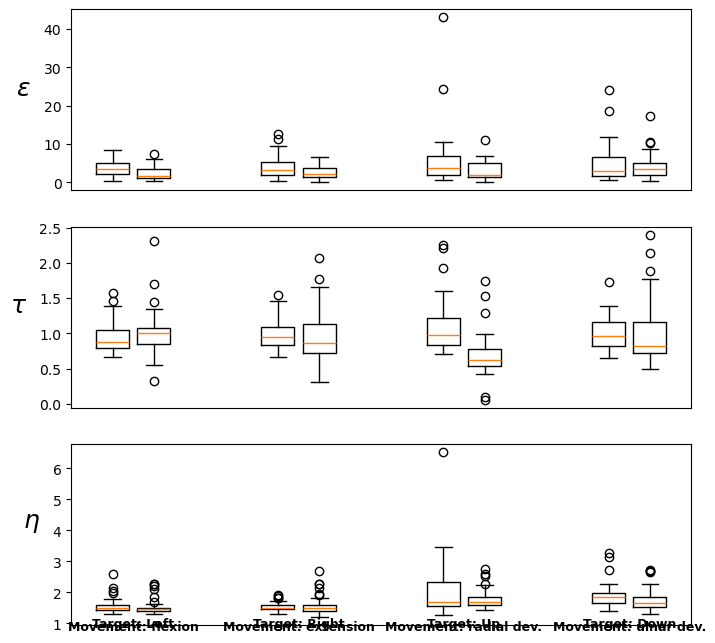

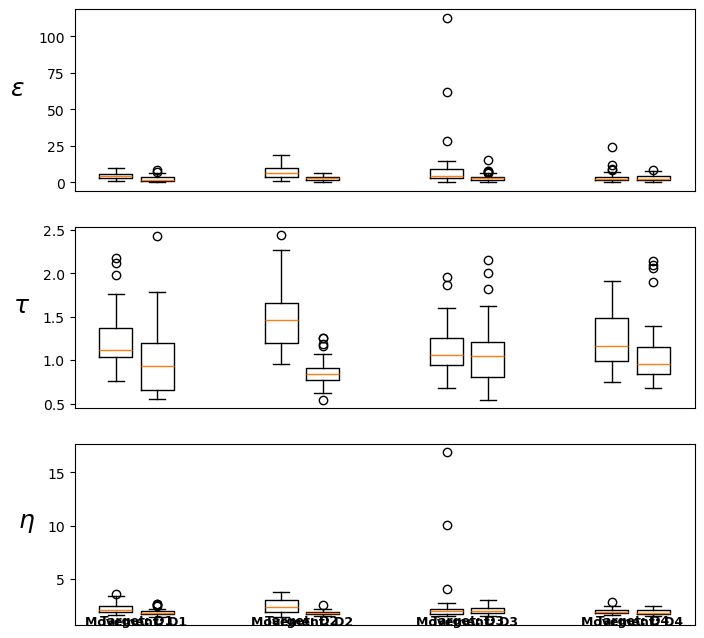

In [20]:
def custom_rejection_criteria(epoch_data):
    # Define custom rejection criteria
    max_amplitude = 100  # Example threshold in units of the data
    if (np.max(np.abs(epoch_data), axis=1) > max_amplitude).any():
        return True  # Reject epoch
    return False  # Keep epoch  

# Apply the custom function to each epoch to create a boolean mask
# This creates a list of booleans, where True means the epoch is "bad" according to the function
bad_epochs_mask = [custom_rejection_criteria(epoch) for epoch in epochsKinematictmp.get_data()]

# Drop the bad epochs using the mask
# The 'drop' method can take a boolean mask or indices
epochsKinematictmp.drop(bad_epochs_mask, reason='custom_criteria')

data3D_Kinematic = epochsKinematictmp.get_data()

time = np.zeros(shape=(data3D_Kinematic.shape[2]), dtype=np.float32)
movement = {1: "Flexion", 2: "Extension", 3: "Radial D.", 4: "Ulnar D.", 5: "D1", 6: "D2", 7: "D3", 8: "D4"}

for x in range(data3D_Kinematic.shape[2]):
    time[x] = x * 1/fs

MotorPerformanceIndices = np.zeros(shape=(data3D_Kinematic.shape[0],6), dtype=np.float32)

for selected_trial in range(0,data3D_Kinematic.shape[0]):    
    #Computing motor performance indices
    X = data3D_Kinematic[selected_trial,0,:]
    Y = data3D_Kinematic[selected_trial,1,:]

    MotorPerformanceIndices[selected_trial, 0] = ComputeAccuracy(movement= movement[targets[selected_trial]], RawData= np.array([X,Y]), movementDirection= "GO")
    MotorPerformanceIndices[selected_trial, 1] = ComputeAccuracy(movement= movement[targets[selected_trial]], RawData= np.array([X,Y]), movementDirection= "GO BACK")

    MotorPerformanceIndices[selected_trial, 2] = ComputeExcecutionTime(movement= movement[targets[selected_trial]], RawData= np.array([X,Y]), movementDirection= "GO")
    MotorPerformanceIndices[selected_trial, 3] = ComputeExcecutionTime(movement= movement[targets[selected_trial]], RawData= np.array([X,Y]), movementDirection= "GO BACK")

    MotorPerformanceIndices[selected_trial, 4] = ComputeTrayectoryEfficiency(movement= movement[targets[selected_trial]], RawData= np.array([X,Y]), movementDirection= "GO")
    MotorPerformanceIndices[selected_trial, 5] = ComputeTrayectoryEfficiency(movement= movement[targets[selected_trial]], RawData= np.array([X,Y]), movementDirection= "GO BACK")

# Define nombres de columnas (siguiendo el orden de tus métricas)
columns = [
    'Accuracy_ForwardMovement', 'Accuracy_BackwardMovement',
    'ExecutionTime_ForwardMovement', 'ExecutionTime_BackwardMovement',
    'TrajectoryEfficiency_ForwardMovement', 'TrajectoryEfficiency_BackwardMovement'
]

# Crea un DataFrame a partir del array de métricas
df = pd.DataFrame(MotorPerformanceIndices, columns=columns)

# Añade columna de índice de trial (opcional)
df.insert(0, 'trial', df.index)

# Guarda como .tsv
output_path = os.path.join(output_dir, f"sub-{subject_id}_MotorPerformanceMetrics.tsv")
df.to_csv(output_path, sep='\t', index=False)

####Motor Performance Indices Box Plots

event_id= {"Flexion":1, "Extension":2, "Radial D.":3, "Ulnar D.":4, "D1":5, "D2":6, "D3":7, "D4":8}

data3D_Kinematic_Flexion = epochsKinematic['1'].get_data()
data3D_Kinematic_Extension = epochsKinematic['2'].get_data()
data3D_Kinematic_Radial = epochsKinematic['3'].get_data()
data3D_Kinematic_Ulnar = epochsKinematic['4'].get_data()
data3D_D1 = epochsKinematic['5'].get_data()
data3D_D2 = epochsKinematic['6'].get_data()
data3D_D3 = epochsKinematic['7'].get_data()
data3D_D4 = epochsKinematic['8'].get_data()

MotorPerformanceIndicesFlexion = np.zeros(shape=(data3D_Kinematic_Flexion.shape[0],6), dtype=np.float32)
MotorPerformanceIndicesExtension = np.zeros(shape=(data3D_Kinematic_Extension.shape[0],6), dtype=np.float32)
MotorPerformanceIndicesRadialD = np.zeros(shape=(data3D_Kinematic_Radial.shape[0],6), dtype=np.float32)
MotorPerformanceIndicesUlnarD = np.zeros(shape=(data3D_Kinematic_Ulnar.shape[0],6), dtype=np.float32)
MotorPerformanceIndicesD1 = np.zeros(shape=(data3D_D1.shape[0],6), dtype=np.float32)
MotorPerformanceIndicesD2 = np.zeros(shape=(data3D_D2.shape[0],6), dtype=np.float32)
MotorPerformanceIndicesD3 = np.zeros(shape=(data3D_D3.shape[0],6), dtype=np.float32)
MotorPerformanceIndicesD4 = np.zeros(shape=(data3D_D4.shape[0],6), dtype=np.float32)

#Compute Motor Performance Indices for each movement type
for selected_trial in range(0,data3D_Kinematic_Flexion.shape[0]):    
    #Computing motor performance indices
    X_Flexion = data3D_Kinematic_Flexion[selected_trial,0,:]
    Y_Flexion = data3D_Kinematic_Flexion[selected_trial,1,:]
    X_Extension = data3D_Kinematic_Extension[selected_trial,0,:]
    Y_Extension = data3D_Kinematic_Extension[selected_trial,1,:]
    X_RadialD = data3D_Kinematic_Radial[selected_trial,0,:]
    Y_RadialD = data3D_Kinematic_Radial[selected_trial,1,:]
    X_UlnarD = data3D_Kinematic_Ulnar[selected_trial,0,:]
    Y_UlnarD = data3D_Kinematic_Ulnar[selected_trial,1,:]
    X_D1 = data3D_D1[selected_trial,0,:]
    Y_D1 = data3D_D1[selected_trial,1,:]
    X_D2 = data3D_D2[selected_trial,0,:]
    Y_D2 = data3D_D2[selected_trial,1,:]
    X_D3 = data3D_D3[selected_trial,0,:]
    Y_D3 = data3D_D3[selected_trial,1,:]
    X_D4 = data3D_D4[selected_trial,0,:]
    Y_D4 = data3D_D4[selected_trial,1,:]


    MotorPerformanceIndicesFlexion[selected_trial, 0] = ComputeAccuracy(movement= "Flexion", RawData= np.array([X_Flexion,Y_Flexion]), movementDirection= "GO")
    MotorPerformanceIndicesFlexion[selected_trial, 1] = ComputeAccuracy(movement= "Flexion", RawData= np.array([X_Flexion,Y_Flexion]), movementDirection= "GO BACK")
    MotorPerformanceIndicesFlexion[selected_trial, 2] = ComputeExcecutionTime(movement= "Flexion", RawData= np.array([X_Flexion,Y_Flexion]), movementDirection= "GO")
    MotorPerformanceIndicesFlexion[selected_trial, 3] = ComputeExcecutionTime(movement= "Flexion", RawData= np.array([X_Flexion,Y_Flexion]), movementDirection= "GO BACK")
    MotorPerformanceIndicesFlexion[selected_trial, 4] = ComputeTrayectoryEfficiency(movement= "Flexion", RawData= np.array([X_Flexion,Y_Flexion]), movementDirection= "GO")
    MotorPerformanceIndicesFlexion[selected_trial, 5] = ComputeTrayectoryEfficiency(movement= "Flexion", RawData= np.array([X_Flexion,Y_Flexion]), movementDirection= "GO BACK")

    MotorPerformanceIndicesExtension[selected_trial, 0] = ComputeAccuracy(movement= "Extension", RawData= np.array([X_Extension,Y_Extension]), movementDirection= "GO")
    MotorPerformanceIndicesExtension[selected_trial, 1] = ComputeAccuracy(movement= "Extension", RawData= np.array([X_Extension,Y_Extension]), movementDirection= "GO BACK")
    MotorPerformanceIndicesExtension[selected_trial, 2] = ComputeExcecutionTime(movement= "Extension", RawData= np.array([X_Extension,Y_Extension]), movementDirection= "GO")
    MotorPerformanceIndicesExtension[selected_trial, 3] = ComputeExcecutionTime(movement= "Extension", RawData= np.array([X_Extension,Y_Extension]), movementDirection= "GO BACK")
    MotorPerformanceIndicesExtension[selected_trial, 4] = ComputeTrayectoryEfficiency(movement= "Extension", RawData= np.array([X_Extension,Y_Extension]), movementDirection= "GO")
    MotorPerformanceIndicesExtension[selected_trial, 5] = ComputeTrayectoryEfficiency(movement= "Extension", RawData= np.array([X_Extension,Y_Extension]), movementDirection= "GO BACK")

    MotorPerformanceIndicesRadialD[selected_trial, 0] = ComputeAccuracy(movement= "Radial D.", RawData= np.array([X_RadialD,Y_RadialD]), movementDirection= "GO")
    MotorPerformanceIndicesRadialD[selected_trial, 1] = ComputeAccuracy(movement= "Radial D.", RawData= np.array([X_RadialD,Y_RadialD]), movementDirection= "GO BACK")
    MotorPerformanceIndicesRadialD[selected_trial, 2] = ComputeExcecutionTime(movement= "Radial D.", RawData= np.array([X_RadialD,Y_RadialD]), movementDirection= "GO")
    MotorPerformanceIndicesRadialD[selected_trial, 3] = ComputeExcecutionTime(movement= "Radial D.", RawData= np.array([X_RadialD,Y_RadialD]), movementDirection= "GO BACK")
    MotorPerformanceIndicesRadialD[selected_trial, 4] = ComputeTrayectoryEfficiency(movement= "Radial D.", RawData= np.array([X_RadialD,Y_RadialD]), movementDirection= "GO")
    MotorPerformanceIndicesRadialD[selected_trial, 5] = ComputeTrayectoryEfficiency(movement= "Radial D.", RawData= np.array([X_RadialD,Y_RadialD]), movementDirection= "GO BACK")

    MotorPerformanceIndicesUlnarD[selected_trial, 0] = ComputeAccuracy(movement= "Ulnar D.", RawData= np.array([X_UlnarD,Y_UlnarD]), movementDirection= "GO")
    MotorPerformanceIndicesUlnarD[selected_trial, 1] = ComputeAccuracy(movement= "Ulnar D.", RawData= np.array([X_UlnarD,Y_UlnarD]), movementDirection= "GO BACK")
    MotorPerformanceIndicesUlnarD[selected_trial, 2] = ComputeExcecutionTime(movement= "Ulnar D.", RawData= np.array([X_UlnarD,Y_UlnarD]), movementDirection= "GO")
    MotorPerformanceIndicesUlnarD[selected_trial, 3] = ComputeExcecutionTime(movement= "Ulnar D.", RawData= np.array([X_UlnarD,Y_UlnarD]), movementDirection= "GO BACK")
    MotorPerformanceIndicesUlnarD[selected_trial, 4] = ComputeTrayectoryEfficiency(movement= "Ulnar D.", RawData= np.array([X_UlnarD,Y_UlnarD]), movementDirection= "GO")
    MotorPerformanceIndicesUlnarD[selected_trial, 5] = ComputeTrayectoryEfficiency(movement= "Ulnar D.", RawData= np.array([X_UlnarD,Y_UlnarD]), movementDirection= "GO BACK")

    MotorPerformanceIndicesD1[selected_trial, 0] = ComputeAccuracy(movement= "D1", RawData= np.array([X_D1,Y_D1]), movementDirection= "GO")
    MotorPerformanceIndicesD1[selected_trial, 1] = ComputeAccuracy(movement= "D1", RawData= np.array([X_D1,Y_D1]), movementDirection= "GO BACK")
    MotorPerformanceIndicesD1[selected_trial, 2] = ComputeExcecutionTime(movement= "D1", RawData= np.array([X_D1,Y_D1]), movementDirection= "GO")
    MotorPerformanceIndicesD1[selected_trial, 3] = ComputeExcecutionTime(movement= "D1", RawData= np.array([X_D1,Y_D1]), movementDirection= "GO BACK")
    MotorPerformanceIndicesD1[selected_trial, 4] = ComputeTrayectoryEfficiency(movement= "D1", RawData= np.array([X_D1,Y_D1]), movementDirection= "GO")
    MotorPerformanceIndicesD1[selected_trial, 5] = ComputeTrayectoryEfficiency(movement= "D1", RawData= np.array([X_D1,Y_D1]), movementDirection= "GO BACK")

    MotorPerformanceIndicesD2[selected_trial, 0] = ComputeAccuracy(movement= "D2", RawData= np.array([X_D2,Y_D2]), movementDirection= "GO")
    MotorPerformanceIndicesD2[selected_trial, 1] = ComputeAccuracy(movement= "D2", RawData= np.array([X_D2,Y_D2]), movementDirection= "GO BACK")
    MotorPerformanceIndicesD2[selected_trial, 2] = ComputeExcecutionTime(movement= "D2", RawData= np.array([X_D2,Y_D2]), movementDirection= "GO")
    MotorPerformanceIndicesD2[selected_trial, 3] = ComputeExcecutionTime(movement= "D2", RawData= np.array([X_D2,Y_D2]), movementDirection= "GO BACK")
    MotorPerformanceIndicesD2[selected_trial, 4] = ComputeTrayectoryEfficiency(movement= "D2", RawData= np.array([X_D2,Y_D2]), movementDirection= "GO")
    MotorPerformanceIndicesD2[selected_trial, 5] = ComputeTrayectoryEfficiency(movement= "D2", RawData= np.array([X_D2,Y_D2]), movementDirection= "GO BACK")

    MotorPerformanceIndicesD3[selected_trial, 0] = ComputeAccuracy(movement= "D3", RawData= np.array([X_D3,Y_D3]), movementDirection= "GO")
    MotorPerformanceIndicesD3[selected_trial, 1] = ComputeAccuracy(movement= "D3", RawData= np.array([X_D3,Y_D3]), movementDirection= "GO BACK")
    MotorPerformanceIndicesD3[selected_trial, 2] = ComputeExcecutionTime(movement= "D3", RawData= np.array([X_D3,Y_D3]), movementDirection= "GO")
    MotorPerformanceIndicesD3[selected_trial, 3] = ComputeExcecutionTime(movement= "D3", RawData= np.array([X_D3,Y_D3]), movementDirection= "GO BACK")
    MotorPerformanceIndicesD3[selected_trial, 4] = ComputeTrayectoryEfficiency(movement= "D3", RawData= np.array([X_D3,Y_D3]), movementDirection= "GO")
    MotorPerformanceIndicesD3[selected_trial, 5] = ComputeTrayectoryEfficiency(movement= "D3", RawData=np.array([X_D3,Y_D3]), movementDirection="GO BACK")

    MotorPerformanceIndicesD4[selected_trial, 0] = ComputeAccuracy(movement= "D4", RawData= np.array([X_D4,Y_D4]), movementDirection= "GO")
    MotorPerformanceIndicesD4[selected_trial, 1] = ComputeAccuracy(movement= "D4", RawData= np.array([X_D4,Y_D4]), movementDirection= "GO BACK")
    MotorPerformanceIndicesD4[selected_trial, 2] = ComputeExcecutionTime(movement= "D4", RawData= np.array([X_D4,Y_D4]), movementDirection= "GO")
    MotorPerformanceIndicesD4[selected_trial, 3] = ComputeExcecutionTime(movement= "D4", RawData= np.array([X_D4,Y_D4]), movementDirection= "GO BACK")
    MotorPerformanceIndicesD4[selected_trial, 4] = ComputeTrayectoryEfficiency(movement= "D4", RawData= np.array([X_D4,Y_D4]), movementDirection= "GO")
    MotorPerformanceIndicesD4[selected_trial, 5] = ComputeTrayectoryEfficiency(movement= "D4", RawData= np.array([X_D4,Y_D4]), movementDirection= "GO BACK")



# Create a figure and an axes object
fig, axs = plt.subplots(3,1, figsize=(8, 8), sharex=True)

# Plot the box plot
axs[0].set_ylabel(r'$\varepsilon$', rotation='horizontal', fontsize=18, labelpad=15)
Accuracy = [MotorPerformanceIndicesFlexion[:, 0], MotorPerformanceIndicesFlexion[:, 1], MotorPerformanceIndicesExtension[:, 0], MotorPerformanceIndicesExtension[:, 1],MotorPerformanceIndicesRadialD[:, 0], MotorPerformanceIndicesRadialD[:, 1],MotorPerformanceIndicesUlnarD[:, 0], MotorPerformanceIndicesUlnarD[:, 1]]
axs[0].boxplot(Accuracy, positions=[0.5,1,2.5,3,4.5,5,6.5,7], widths=0.4)
axs[0].tick_params(axis='x', which='both', bottom=False, labelbottom=False)

axs[1].set_ylabel(r'$\tau$', rotation='horizontal', fontsize=18, labelpad=15)
Time = [MotorPerformanceIndicesFlexion[:, 2][~np.isnan(MotorPerformanceIndicesFlexion[:, 2])], MotorPerformanceIndicesFlexion[:, 3][~np.isnan(MotorPerformanceIndicesFlexion[:, 3])], MotorPerformanceIndicesExtension[:, 2][~np.isnan(MotorPerformanceIndicesExtension[:, 2])], MotorPerformanceIndicesExtension[:, 3][~np.isnan(MotorPerformanceIndicesExtension[:, 3])],MotorPerformanceIndicesRadialD[:, 2][~np.isnan(MotorPerformanceIndicesRadialD[:, 2])], MotorPerformanceIndicesRadialD[:, 3][~np.isnan(MotorPerformanceIndicesRadialD[:, 3])],MotorPerformanceIndicesUlnarD[:, 2][~np.isnan(MotorPerformanceIndicesUlnarD[:, 2])], MotorPerformanceIndicesUlnarD[:, 3][~np.isnan(MotorPerformanceIndicesUlnarD[:, 3])]]
axs[1].boxplot(Time, positions=[0.5,1,2.5,3,4.5,5,6.5,7], widths=0.4)
axs[1].tick_params(axis='x', which='both', bottom=False, labelbottom=False)

axs[2].set_ylabel(r'$\eta$', rotation='horizontal', fontsize=18, labelpad=15)
Efficiency = [MotorPerformanceIndicesFlexion[:, 4], MotorPerformanceIndicesFlexion[:, 5], MotorPerformanceIndicesExtension[:, 4], MotorPerformanceIndicesExtension[:, 5],MotorPerformanceIndicesRadialD[:, 4], MotorPerformanceIndicesRadialD[:, 5],MotorPerformanceIndicesUlnarD[:, 4], MotorPerformanceIndicesUlnarD[:, 5]]
axs[2].boxplot(Efficiency, positions=[0.5,1,2.5,3,4.5,5,6.5,7], widths=0.4)
axs[2].tick_params(axis='x', which='both', bottom=False, labelbottom=False)

ymin = axs[2].get_ylim()[0]
axs[2].text(0.75, ymin-0.15, 'Target: Left', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold')
axs[2].text(0.75, ymin-0.25, 'Movement: flexion', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold')
axs[2].text(2.75, ymin-0.15, 'Target: Right', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold')
axs[2].text(2.75, ymin-0.25, 'Movement: extension', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold')
axs[2].text(4.75, ymin-0.15, 'Target: Up', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold')
axs[2].text(4.75, ymin-0.25, 'Movement: radial dev.', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold')
axs[2].text(6.75, ymin-0.15, 'Target: Down', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold')
axs[2].text(6.75, ymin-0.25, 'Movement: ulnar dev.', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold')


# Display the plot
plt.show()
output_path = os.path.join(output_dir, f"sub-{subject_id}_KinematicPerformanceMetrics.pdf")
fig.savefig(output_path, dpi=600, bbox_inches='tight') # Save the figure

# Create a figure and an axes object
fig2, axs2 = plt.subplots(3,1, figsize=(8, 8), sharex=True)

# Plot the box plot
axs2[0].set_ylabel(r'$\varepsilon$', rotation='horizontal', fontsize=18, labelpad=15)
Accuracy = [MotorPerformanceIndicesD1[:, 0], MotorPerformanceIndicesD1[:, 1], MotorPerformanceIndicesD2[:, 0], MotorPerformanceIndicesD2[:, 1],MotorPerformanceIndicesD3[:, 0], MotorPerformanceIndicesD3[:, 1],MotorPerformanceIndicesD4[:, 0], MotorPerformanceIndicesD4[:, 1]]
axs2[0].boxplot(Accuracy, positions=[0.5,1,2.5,3,4.5,5,6.5,7], widths=0.4)
axs2[0].tick_params(axis='x', which='both', bottom=False, labelbottom=False)

axs2[1].set_ylabel(r'$\tau$', rotation='horizontal', fontsize=18, labelpad=15)
Time = [MotorPerformanceIndicesD1[:, 2][~np.isnan(MotorPerformanceIndicesD1[:, 2])], MotorPerformanceIndicesD1[:, 3][~np.isnan(MotorPerformanceIndicesD1[:, 3])], MotorPerformanceIndicesD2[:, 2][~np.isnan(MotorPerformanceIndicesD2[:, 2])], MotorPerformanceIndicesD2[:, 3][~np.isnan(MotorPerformanceIndicesD2[:, 3])],MotorPerformanceIndicesD3[:, 2][~np.isnan(MotorPerformanceIndicesD3[:, 2])], MotorPerformanceIndicesD3[:, 3][~np.isnan(MotorPerformanceIndicesD3[:, 3])],MotorPerformanceIndicesD4[:, 2][~np.isnan(MotorPerformanceIndicesD4[:, 2])], MotorPerformanceIndicesD4[:, 3][~np.isnan(MotorPerformanceIndicesD4[:, 3])]]
axs2[1].boxplot(Time, positions=[0.5,1,2.5,3,4.5,5,6.5,7], widths=0.4)
axs2[1].tick_params(axis='x', which='both', bottom=False, labelbottom=False)

axs2[2].set_ylabel(r'$\eta$', rotation='horizontal', fontsize=18, labelpad=15)
Efficiency = [MotorPerformanceIndicesD1[:, 4], MotorPerformanceIndicesD1[:, 5], MotorPerformanceIndicesD2[:, 4], MotorPerformanceIndicesD2[:, 5],MotorPerformanceIndicesD3[:, 4], MotorPerformanceIndicesD3[:, 5],MotorPerformanceIndicesD4[:, 4], MotorPerformanceIndicesD4[:, 5]]
axs2[2].boxplot(Efficiency, positions=[0.5,1,2.5,3,4.5,5,6.5,7], widths=0.4)
axs2[2].tick_params(axis='x', which='both', bottom=False, labelbottom=False)

ymin = axs2[2].get_ylim()[0]
axs2[2].text(0.75, ymin-0.15, 'Target: D1', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold')
axs2[2].text(0.75, ymin-0.25, 'Movement: D1', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold')
axs2[2].text(2.75, ymin-0.15, 'Target: D2', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold')
axs2[2].text(2.75, ymin-0.25, 'Movement: D2', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold')
axs2[2].text(4.75, ymin-0.15, 'Target: D3', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold')
axs2[2].text(4.75, ymin-0.25, 'Movement: D3', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold')
axs2[2].text(6.75, ymin-0.15, 'Target: D4', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold')
axs2[2].text(6.75, ymin-0.25, 'Movement: D4', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold')


# Display the plot
plt.show()